# Which struggling firms recover? Predicting the recovery of marginal firms under economic shocks

**Question.** When an economic shock pushes companies into distress, which ones climb back out the next year, and do the warning signs differ from calm periods?

**Setup** (team project, Financial Big Data Analytics Bootcamp, Ubion, Jun–Jul 2022; I was team lead):

- **Firms:** Korean companies subject to external audit (*oegam* firms). They are smaller and more fragile than listed companies, and are a key focus for regulators and lenders.
- **Marginal firm** (two definitions, used separately):
  1. *Interest coverage:* interest coverage ratio (operating income / interest expense) below 1 for two consecutive years, adapted from the Bank of Korea definition.
  2. *Operating loss:* operating loss for two consecutive years, adapted from Korean credit guarantee agencies.
- **Recovery (target = 1):** in the third year, interest coverage is at least 1 (or operating income turns positive).
- **Periods:** three shock windows (dot-com bust 2000–01, global financial crisis 2007–08, European debt crisis 2011–12) and three calm windows (2014–15, 2015–16, 2016–17). Two definitions × six windows = **12 datasets**.
- **Features:** 28 candidates (20 standard financial ratios, 5 Bank of Korea vulnerability ratios and 3 firm-type dummies), selected per dataset with a logit model.

> **About the data.** The original analysis used TS2000, a licensed Korean financial-statement database that cannot be shared. This notebook runs the full pipeline on a **synthetic panel** with the same line items (`src/synthetic_ts2000.py`). Every number produced below comes from simulated data. The original results are reproduced from the final presentation in Section 8 and in the README. To run on real data, point `TS2000_PATH` to a firm-year file with the same columns.

In [1]:
import sys, warnings
warnings.filterwarnings('ignore')
sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, roc_auc_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

from synthetic_ts2000 import simulate_panel

SEED = 42
TS2000_PATH = None   # path to a real firm-year file with the same columns; None = synthetic data
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_colwidth', None)

## 1. Firm-year panel

In [2]:
panel = pd.read_csv(TS2000_PATH) if TS2000_PATH else simulate_panel(seed=SEED)
print(f'{len(panel):,} firm-years, {panel.firm_id.nunique():,} firms, {panel.year.min()}-{panel.year.max()}')
panel.head()

239,043 firm-years, 16,000 firms, 1998-2018


,firm_id,year,total_assets,current_assets,cash,receivables,inventory,tangible_assets,total_liabilities,current_liabilities,...,equity,sales,cogs,sga,operating_income,interest_expense,net_income,operating_cash_flow,manufacturing,financial_or_spc
0,7,1998,6.128293e+09,2.384460e+09,7.347353e+08,9.725421e+08,5.933101e+08,1.727726e+09,2.384222e+09,1.429054e+09,...,3.744071e+09,5.620573e+09,3.898199e+09,1.474148e+09,2.482256e+08,1.304964e+08,9.406384e+07,1.284161e+08,0,0
1,19,1998,2.238026e+10,5.174499e+09,1.799888e+09,1.659806e+09,2.309851e+09,1.421381e+10,9.204980e+09,7.382787e+09,...,1.317528e+10,4.957542e+10,3.503905e+10,1.197005e+10,2.566318e+09,3.364741e+08,1.462536e+09,1.439953e+09,1,0
2,29,1998,1.726685e+09,1.231890e+09,2.134187e+08,6.704796e+08,2.797094e+08,2.933867e+08,3.926180e+08,2.293852e+08,...,1.334067e+09,2.670314e+09,1.520984e+09,1.040007e+09,1.093234e+08,1.340129e+07,7.727954e+07,1.075065e+08,0,0
3,32,1998,1.774258e+10,7.348647e+09,1.429061e+09,3.504194e+09,2.001391e+09,7.964018e+09,1.726820e+10,1.121401e+10,...,4.743764e+08,1.051802e+10,7.864730e+09,1.841395e+09,8.118984e+08,4.683904e+08,5.223503e+08,5.785391e+08,1,0
4,37,1998,1.540296e+09,5.274695e+08,4.188798e+07,2.337136e+08,1.125094e+08,6.107208e+08,3.095062e+08,2.620503e+08,...,1.230790e+09,1.185500e+09,1.041063e+09,8.289757e+07,6.154031e+07,8.118991e+06,6.112398e+07,NaN,1,0


## 2. Financial ratios

In the original project, TS2000's precomputed ratios had many blanks and errors, and ratios with negative denominators were misleading. The team therefore pulled the **raw line items** and computed every ratio directly, which this function reproduces.

In [3]:
def compute_ratios(panel):
    d = panel.sort_values(['firm_id', 'year']).copy()
    prev = d.groupby('firm_id')[['total_assets', 'current_assets', 'sales']].shift(1)
    r = d[['firm_id', 'year', 'financial_or_spc']].copy()

    # growth (3)
    r['total_asset_growth'] = d['total_assets'] / prev['total_assets'] - 1
    r['current_asset_growth'] = d['current_assets'] / prev['current_assets'] - 1
    r['sales_growth'] = d['sales'] / prev['sales'] - 1
    # profitability (5)
    r['net_margin'] = d['net_income'] / d['sales']
    r['cogs_to_sales'] = d['cogs'] / d['sales']
    r['roe'] = d['net_income'] / d['equity']
    r['roa'] = d['net_income'] / d['total_assets']
    r['sga_to_sales'] = d['sga'] / d['sales']
    # activity (4)
    r['receivables_turnover'] = d['sales'] / d['receivables']
    r['inventory_turnover'] = d['cogs'] / d['inventory']
    r['asset_turnover'] = d['sales'] / d['total_assets']
    r['tangible_asset_turnover'] = d['sales'] / d['tangible_assets']
    # stability (8)
    r['debt_to_equity'] = d['total_liabilities'] / d['equity']
    r['current_ratio'] = d['current_assets'] / d['current_liabilities']
    r['equity_multiplier'] = d['total_assets'] / d['equity']
    r['quick_ratio'] = (d['current_assets'] - d['inventory']) / d['current_liabilities']
    r['fixed_ratio'] = (d['total_assets'] - d['current_assets']) / d['equity']
    r['cash_ratio'] = d['cash'] / d['current_liabilities']
    r['net_working_capital_ratio'] = (d['current_assets'] - d['current_liabilities']) / d['total_assets']
    r['borrowings_to_assets'] = d['borrowings'] / d['total_assets']
    # leverage, Bank of Korea vulnerability ratios (3)
    r['debt_to_sales'] = d['total_liabilities'] / d['sales']
    r['debt_to_cash_flow'] = d['total_liabilities'] / d['operating_cash_flow']
    r['current_liabilities_share'] = d['current_liabilities'] / d['total_liabilities']
    # liquidity, Bank of Korea vulnerability ratios (2)
    r['cash_flow_to_sales'] = d['operating_cash_flow'] / d['sales']
    r['avg_borrowing_rate'] = d['interest_expense'] / d['borrowings']
    # firm type (dummies are tiered later, within each dataset)
    r['sales'], r['total_assets'] = d['sales'], d['total_assets']
    r['non_manufacturing'] = 1 - d['manufacturing']
    # definition variables: used only to build labels, never as features
    r['interest_coverage'] = d['operating_income'] / d['interest_expense']
    r['operating_income'] = d['operating_income']
    return r

ratios = compute_ratios(panel)

RATIO_FEATURES = ['total_asset_growth', 'current_asset_growth', 'sales_growth',
                  'net_margin', 'cogs_to_sales', 'roe', 'roa', 'sga_to_sales',
                  'receivables_turnover', 'inventory_turnover', 'asset_turnover', 'tangible_asset_turnover',
                  'debt_to_equity', 'current_ratio', 'equity_multiplier', 'quick_ratio', 'fixed_ratio',
                  'cash_ratio', 'net_working_capital_ratio', 'borrowings_to_assets',
                  'debt_to_sales', 'debt_to_cash_flow', 'current_liabilities_share',
                  'cash_flow_to_sales', 'avg_borrowing_rate']
DUMMIES = ['sales_tier', 'non_manufacturing', 'asset_tier']
CANDIDATES = RATIO_FEATURES + DUMMIES
print(f'{len(RATIO_FEATURES)} ratios + {len(DUMMIES)} dummies = {len(CANDIDATES)} candidate features')

25 ratios + 3 dummies = 28 candidate features


## 3. Building the 12 datasets

For a window starting in year *y*:

- **Marginal firms:** below the threshold in both *y* and *y*+1.
- **Features:** ratios from year *y*+1, the last year the firm was marginal. This is the information available when predicting.
- **Label:** whether the firm recovers in year *y*+2.

Cleaning follows the original: drop financial firms and special-purpose companies, drop missing and infinite values, and winsorize each ratio at 1% per tail. Sales and asset tiers split firms at the 25th and 75th percentiles (0 / 1 / 2).

In [4]:
WINDOWS = {'shock': [2000, 2007, 2011], 'calm': [2014, 2015, 2016]}
CRITERIA = {
    'interest_coverage': (lambda r: r['interest_coverage'] < 1, lambda r: r['interest_coverage'] >= 1),
    'operating_loss':    (lambda r: r['operating_income'] < 0,  lambda r: r['operating_income'] > 0),
}

def tier(x):
    q1, q3 = x.quantile([0.25, 0.75])
    return np.select([x < q1, x < q3], [0, 1], 2)

def build_dataset(ratios, start, criterion, feature_year_offset=1):
    is_marginal, is_recovered = CRITERIA[criterion]
    by_year = {y: ratios[ratios.year == y].set_index('firm_id') for y in (start, start + 1, start + 2)}
    y0, y1, y2 = by_year[start], by_year[start + 1], by_year[start + 2]
    firms = y0.index[is_marginal(y0)].intersection(y1.index[is_marginal(y1)]).intersection(y2.index)

    feature_rows = by_year[start + feature_year_offset].loc[firms]
    d = feature_rows[RATIO_FEATURES + ['sales', 'total_assets', 'non_manufacturing', 'financial_or_spc']].copy()
    d['recovered'] = is_recovered(y2.loc[firms]).astype(int)

    d = d[d.pop('financial_or_spc') == 0]
    d = d.replace([np.inf, -np.inf], np.nan).dropna()
    d[RATIO_FEATURES] = d[RATIO_FEATURES].clip(d[RATIO_FEATURES].quantile(0.01),
                                               d[RATIO_FEATURES].quantile(0.99), axis=1)
    d['sales_tier'], d['asset_tier'] = tier(d.pop('sales')), tier(d.pop('total_assets'))
    return d.reset_index(drop=True)

def window_label(start):
    return f"{str(start)[2:]}-{str(start + 1)[2:]}"

datasets = {(c, p, s): build_dataset(ratios, s, c) for c in CRITERIA for p, ws in WINDOWS.items() for s in ws}
summary = pd.DataFrame([{'criterion': c, 'period': p, 'window': window_label(s), 'firms': len(d),
                         'recovered': d.recovered.sum(), 'recovery rate': d.recovered.mean()}
                        for (c, p, s), d in datasets.items()])
summary.round(3)

,criterion,period,window,firms,recovered,recovery rate
0,interest_coverage,shock,00-01,1186,428,0.361
1,interest_coverage,shock,07-08,2959,799,0.270
2,interest_coverage,shock,11-12,4436,1264,0.285
3,interest_coverage,calm,14-15,2541,726,0.286
4,interest_coverage,calm,15-16,2244,592,0.264
5,interest_coverage,calm,16-17,2078,599,0.288
6,operating_loss,shock,00-01,785,305,0.389
7,operating_loss,shock,07-08,1968,624,0.317
8,operating_loss,shock,11-12,3271,1107,0.338
9,operating_loss,calm,14-15,1680,539,0.321


## 4. Feature selection with a logit model

As in the original, selection uses a logit model on each dataset (here, on the training split only, so the test set does not influence it):

1. When two candidates correlate above 0.8, keep the more significant one.
2. Backward elimination: drop the least significant variable one at a time until every p-value is below 0.05.

In [5]:
def select_features(X, y, alpha=0.05, corr_limit=0.8):
    cols = [c for c in X.columns if X[c].std() > 0]
    Z = (X[cols] - X[cols].mean()) / X[cols].std()

    def pvalues(columns):
        with warnings.catch_warnings():
            warnings.simplefilter('ignore')   # quasi-separation warnings on small windows
            model = sm.Logit(y, sm.add_constant(Z[columns])).fit(disp=0, maxiter=200, method='bfgs')
        return model.pvalues.drop('const')

    p = pvalues(cols)
    corr = Z.corr().abs()
    for i, a in enumerate(cols):
        for b in cols[i + 1:]:
            if a in cols and b in cols and corr.loc[a, b] > corr_limit:
                cols.remove(a if p[a] > p[b] else b)
    while cols:
        p = pvalues(cols)
        if p.max() < alpha:
            break
        cols.remove(p.idxmax())
    return cols

splits, selected = {}, {}
for key, d in datasets.items():
    X_tr, X_te, y_tr, y_te = train_test_split(d[CANDIDATES], d['recovered'], test_size=0.2,
                                              stratify=d['recovered'], random_state=SEED)
    splits[key] = (X_tr, X_te, y_tr, y_te)
    selected[key] = select_features(X_tr, y_tr)

pd.DataFrame([{'criterion': c, 'period': p, 'window': window_label(s), 'n selected': len(f),
               'selected features': ', '.join(f)} for (c, p, s), f in selected.items()])

,criterion,period,window,n selected,selected features
0,interest_coverage,shock,00-01,2,"roa, avg_borrowing_rate"
1,interest_coverage,shock,07-08,5,"net_margin, cogs_to_sales, asset_turnover, current_ratio, debt_to_cash_flow"
2,interest_coverage,shock,11-12,7,"cogs_to_sales, roa, sga_to_sales, asset_turnover, borrowings_to_assets, avg_borrowing_rate, asset_tier"
3,interest_coverage,calm,14-15,6,"net_margin, roe, asset_turnover, current_ratio, current_liabilities_share, sales_tier"
4,interest_coverage,calm,15-16,8,"cogs_to_sales, roa, sga_to_sales, receivables_turnover, net_working_capital_ratio, borrowings_to_assets, debt_to_sales, avg_borrowing_rate"
5,interest_coverage,calm,16-17,4,"net_margin, roe, inventory_turnover, debt_to_equity"
6,operating_loss,shock,00-01,1,roa
7,operating_loss,shock,07-08,4,"roe, roa, inventory_turnover, borrowings_to_assets"
8,operating_loss,shock,11-12,7,"net_margin, cogs_to_sales, roe, asset_turnover, current_ratio, fixed_ratio, debt_to_sales"
9,operating_loss,calm,14-15,4,"net_margin, asset_turnover, borrowings_to_assets, sales_tier"


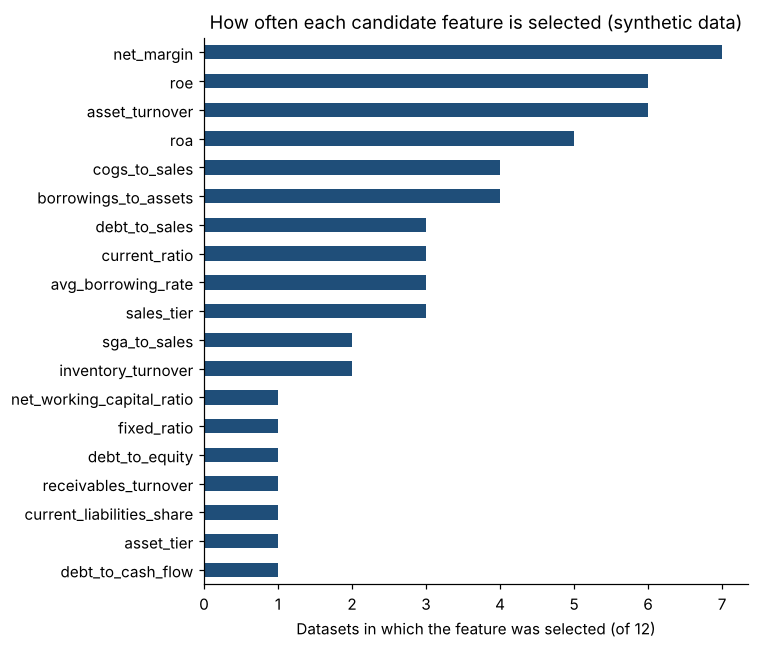

In [6]:
# how often each feature is selected across the 12 datasets
counts = pd.Series([f for fs in selected.values() for f in fs]).value_counts()
fig, ax = plt.subplots(figsize=(7, 6))
counts.sort_values().plot.barh(ax=ax, color='#1f4e79')
ax.set_xlabel('Datasets in which the feature was selected (of 12)')
ax.set_title('How often each candidate feature is selected (synthetic data)')
plt.tight_layout(); plt.show()

## 5. Models

Six models, tuned with 5-fold cross-validated grid search on F1, using an 80/20 train/test split. The grids are trimmed versions of the original ones. The original also had a Keras neural network; here the scikit-learn MLP covers neural networks. Scores are averaged over the three windows in each period, as in the original presentation.

In [7]:
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
MODELS = {
    'Logistic': (make_pipeline(StandardScaler(), LogisticRegression(solver='liblinear', max_iter=500)),
                 {'logisticregression__C': [0.01, 0.1, 1, 10, 100], 'logisticregression__penalty': ['l1', 'l2']}),
    'Decision Tree': (DecisionTreeClassifier(random_state=SEED),
                      {'max_depth': [2, 3, 4, 5, 6, 8], 'min_samples_split': [2, 4], 'max_features': [None, 'sqrt']}),
    'kNN': (make_pipeline(StandardScaler(), KNeighborsClassifier()),
            {'kneighborsclassifier__n_neighbors': [3, 5, 7, 9], 'kneighborsclassifier__weights': ['uniform', 'distance']}),
    'Neural net (MLP)': (make_pipeline(StandardScaler(), MLPClassifier(max_iter=500, early_stopping=True, random_state=SEED)),
                         {'mlpclassifier__hidden_layer_sizes': [(16,), (32,), (32, 16), (64, 32, 16)],
                          'mlpclassifier__activation': ['relu', 'tanh']}),
    'Random Forest': (RandomForestClassifier(random_state=SEED, n_jobs=-1),
                      {'n_estimators': [100, 300], 'min_samples_leaf': [2, 4]}),
    'XGBoost': (XGBClassifier(eval_metric='logloss', random_state=SEED, n_jobs=-1),
                {'n_estimators': [100, 300], 'learning_rate': [0.03, 0.1], 'max_depth': [3, 5], 'gamma': [0, 1]}),
}

def fit_best(name, X, y):
    model, grid = MODELS[name]
    return GridSearchCV(model, grid, scoring='f1', cv=cv, n_jobs=-1).fit(X, y).best_estimator_

rows, best_models = [], {}
for key, (X_tr, X_te, y_tr, y_te) in splits.items():
    cols = selected[key]
    for name in MODELS:
        m = fit_best(name, X_tr[cols], y_tr)
        best_models[key, name] = m
        rows.append({'criterion': key[0], 'period': key[1], 'window': window_label(key[2]), 'model': name,
                     'f1': f1_score(y_te, m.predict(X_te[cols])),
                     'roc_auc': roc_auc_score(y_te, m.predict_proba(X_te[cols])[:, 1])})
results = pd.DataFrame(rows)
table = results.groupby(['criterion', 'period', 'model'])[['f1', 'roc_auc']].mean().unstack(['criterion', 'period'])
table.round(3)

f1                               \
criterion        interest_coverage        operating_loss          
period                        calm  shock           calm  shock   
model                                                             
Decision Tree                0.335  0.506          0.298  0.545   
Logistic                     0.288  0.534          0.221  0.526   
Neural net (MLP)             0.351  0.494          0.284  0.545   
Random Forest                0.293  0.501          0.296  0.509   
XGBoost                      0.327  0.497          0.321  0.521   
kNN                          0.310  0.447          0.361  0.478   

                           roc_auc                               
criterion        interest_coverage        operating_loss         
period                        calm  shock           calm  shock  
model                                                            
Decision Tree                0.658  0.757          0.584  0.735  
Logistic                     0.736  0.786          0.646  0.761  
Neural net (MLP)             0.727  0.767          0.647  0.750  
Random Forest                0.701  0.762          0.601  0.731  
XGBoost                      0.688  0.765          0.592  0.752  
kNN                          0.628  0.694          0.580  0.697

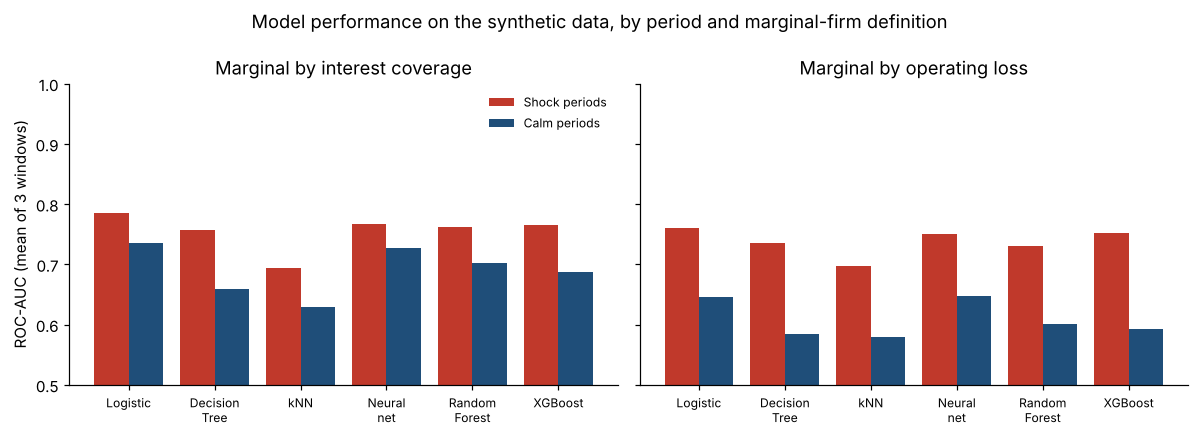

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
order = list(MODELS)
for ax, crit in zip(axes, CRITERIA):
    sub = results[results.criterion == crit].groupby(['model', 'period'])['roc_auc'].mean().unstack().loc[order]
    x = np.arange(len(order))
    ax.bar(x - 0.2, sub['shock'], 0.4, label='Shock periods', color='#c0392b')
    ax.bar(x + 0.2, sub['calm'], 0.4, label='Calm periods', color='#1f4e79')
    ax.set_xticks(x, [m.replace(' (MLP)', '').replace(' ', '\n') for m in order], fontsize=8)
    ax.set_title(f"Marginal by {crit.replace('_', ' ')}")
    ax.set_ylim(0.5, 1.0)
axes[0].set_ylabel('ROC-AUC (mean of 3 windows)')
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle('Model performance on the synthetic data, by period and marginal-firm definition')
plt.tight_layout(); plt.show()

## 6. Robustness: train on one window, test on another

Following the original robustness check, each model is trained on one window and tested on another window of the same period type (3 × 2 = 6 pairs per period and definition), keeping the features and hyperparameters selected on the training window.

In [9]:
rows = []
for crit in CRITERIA:
    for period, starts in WINDOWS.items():
        for s_train in starts:
            for s_test in starts:
                if s_train == s_test:
                    continue
                cols = selected[crit, period, s_train]
                test = datasets[crit, period, s_test]
                for name in MODELS:
                    m = best_models[(crit, period, s_train), name]
                    rows.append({'criterion': crit, 'period': period, 'model': name,
                                 'f1': f1_score(test['recovered'], m.predict(test[cols])),
                                 'roc_auc': roc_auc_score(test['recovered'], m.predict_proba(test[cols])[:, 1])})
robust = pd.DataFrame(rows).groupby(['criterion', 'period', 'model'])[['f1', 'roc_auc']].mean()
change = (robust - results.groupby(['criterion', 'period', 'model'])[['f1', 'roc_auc']].mean()).add_suffix(' change')
robust.join(change).round(3)

f1  roc_auc  f1 change  \
criterion         period model                                         
interest_coverage calm   Decision Tree     0.315    0.647     -0.020   
                         Logistic          0.260    0.726     -0.028   
                         Neural net (MLP)  0.327    0.718     -0.024   
                         Random Forest     0.289    0.700     -0.003   
                         XGBoost           0.324    0.687     -0.002   
                         kNN               0.339    0.629      0.030   
                  shock  Decision Tree     0.465    0.727     -0.040   
                         Logistic          0.458    0.776     -0.077   
                         Neural net (MLP)  0.420    0.769     -0.074   
                         Random Forest     0.436    0.749     -0.065   
                         XGBoost           0.453    0.749     -0.044   
                         kNN               0.429    0.680     -0.018   
operating_loss    calm   Decision Tree     0.353    0.631      0.055   
                         Logistic          0.317    0.693      0.096   
                         Neural net (MLP)  0.396    0.691      0.112   
                         Random Forest     0.363    0.655      0.067   
                         XGBoost           0.378    0.654      0.057   
                         kNN               0.379    0.625      0.019   
                  shock  Decision Tree     0.546    0.730      0.001   
                         Logistic          0.512    0.761     -0.014   
                         Neural net (MLP)  0.541    0.754     -0.004   
                         Random Forest     0.482    0.715     -0.027   
                         XGBoost           0.501    0.746     -0.020   
                         kNN               0.484    0.686      0.006   

                                           roc_auc change  
criterion         period model                             
interest_coverage calm   Decision Tree             -0.011  
                         Logistic                  -0.010  
                         Neural net (MLP)          -0.008  
                         Random Forest             -0.001  
                         XGBoost                   -0.001  
                         kNN                        0.000  
                  shock  Decision Tree             -0.030  
                         Logistic                  -0.010  
                         Neural net (MLP)           0.002  
                         Random Forest             -0.013  
                         XGBoost                   -0.016  
                         kNN                       -0.015  
operating_loss    calm   Decision Tree              0.046  
                         Logistic                   0.047  
                         Neural net (MLP)           0.043  
                         Random Forest              0.054  
                         XGBoost                    0.061  
                         kNN                        0.045  
                  shock  Decision Tree             -0.005  
                         Logistic                  -0.000  
                         Neural net (MLP)           0.004  
                         Random Forest             -0.016  
                         XGBoost                   -0.006  
                         kNN                       -0.011

## 7. Why the year of the features matters

The original analysis used ratios from the two marginal years only; the third year served only to assign the label. That rule matters. If ratios came from the **recovery year itself** (*y*+2), they would already describe the outcome; profitability ratios in particular are almost the label. The cell below rebuilds the interest-coverage datasets with outcome-year features to show how far scores would be inflated.

In [10]:
rows = []
for period, starts in WINDOWS.items():
    for s in starts:
        for label, offset in [('year y+1 (last marginal year)', 1), ('year y+2 (outcome year)', 2)]:
            d = build_dataset(ratios, s, 'interest_coverage', feature_year_offset=offset)
            X_tr, X_te, y_tr, y_te = train_test_split(d[CANDIDATES], d['recovered'], test_size=0.2,
                                                      stratify=d['recovered'], random_state=SEED)
            m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_tr, y_tr)
            rows.append({'features from': label, 'period': period,
                         'roc_auc': roc_auc_score(y_te, m.predict_proba(X_te)[:, 1])})
pd.DataFrame(rows).groupby(['features from', 'period'])['roc_auc'].mean().unstack().round(3)

period,calm,shock
features from,,
year y+1 (last marginal year),0.747,0.785
year y+2 (outcome year),0.991,0.989


## 8. Original results (real TS2000 data, from the final presentation)

Mean of the three windows in each period. These numbers come from the real data and cannot be reproduced here.

**Interest coverage definition**

| Model | Shock F1 | Shock ROC-AUC | Calm F1 | Calm ROC-AUC |
|---|---|---|---|---|
| Logistic | **0.855** | **0.901** | **0.888** | **0.919** |
| Decision Tree | 0.677 | 0.766 | 0.734 | 0.804 |
| kNN | 0.478 | 0.620 | 0.602 | 0.705 |
| ANN | 0.470 | 0.662 | 0.757 | 0.818 |
| Random Forest | 0.757 | 0.843 | 0.814 | 0.861 |
| XGBoost | 0.764 | 0.830 | 0.831 | 0.875 |
| DNN | 0.665 | 0.756 | 0.782 | 0.869 |

**Operating loss definition**

| Model | Shock F1 | Shock ROC-AUC | Calm F1 | Calm ROC-AUC |
|---|---|---|---|---|
| Logistic | 0.761 | 0.827 | 0.848 | 0.889 |
| Decision Tree | 0.803 | **0.851** | 0.792 | 0.866 |
| kNN | 0.785 | 0.820 | 0.778 | 0.825 |
| ANN | 0.750 | 0.787 | 0.855 | 0.891 |
| Random Forest | 0.803 | 0.834 | 0.841 | 0.875 |
| XGBoost | **0.813** | 0.846 | 0.846 | 0.881 |
| DNN | 0.793 | 0.831 | **0.885** | **0.945** |

**Findings reported in the original project**

- Profitability ratios were significant in every dataset; sales, asset and borrowing-related ratios in most.
- The marginal-firm definition (interest coverage vs. operating loss) changed the selected features more than the period type did.
- Ensemble models (random forest, XGBoost) performed well across all datasets and held up best in the cross-window check; neural networks varied the most.

## 9. Takeaways and what I would do next

- **Pipeline:** this notebook reconstructs the full workflow (ratio construction, two marginal-firm definitions, six windows, logit-based selection, six tuned models and a cross-window check) so it can be rerun on licensed data.
- **Keep features before the outcome.** Section 7 shows how much outcome-year ratios would inflate scores; the original analysis avoided this by using only the two marginal years.
- **Limitations noted in the original:** annual year-end data cannot capture shocks that start mid-year, two-year windows may not fit every crisis, and the lag between a shock and distress or recovery was not modeled.
- **Next steps:** define shock windows by when the shock actually hit rather than by calendar year, add lagged variables, and compare more definitions of a marginal firm.